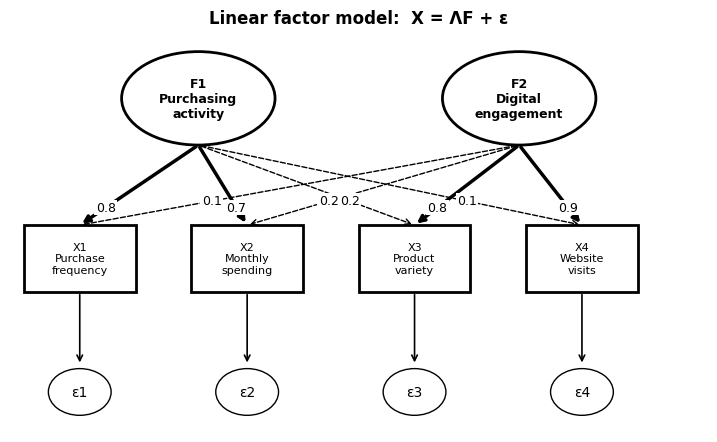

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse, Rectangle

L = np.array([[0.8,0.1],[0.7,0.2],[0.2,0.8],[0.1,0.9]])   # loadings

fig, ax = plt.subplots(figsize=(9,5.2))
ax.set_xlim(0,10); ax.set_ylim(0,6); ax.axis("off")

fx = [2.7, 7.3]                 # x-positions of factors
ox = [1, 3.4, 5.8, 8.2]         # x-positions of observed variables

# latent factors (ellipses)
for x, lab in zip(fx, ["F1\nPurchasing\nactivity", "F2\nDigital\nengagement"]):
    ax.add_patch(Ellipse((x,5), 2.2, 1.4, fill=False, lw=2))
    ax.text(x, 5, lab, ha="center", va="center", weight="bold", fontsize=9)

names = ["X1\nPurchase\nfrequency","X2\nMonthly\nspending","X3\nProduct\nvariety","X4\nWebsite\nvisits"]
for i, (x, nm) in enumerate(zip(ox, names)):
    # observed variable (rectangle)
    ax.add_patch(Rectangle((x-.8, 2.1), 1.6, 1, fill=False, lw=2))
    ax.text(x, 2.6, nm, ha="center", va="center", fontsize=8)
    # unique error
    ax.annotate("", xy=(x,2.1), xytext=(x,1.0), arrowprops=dict(arrowstyle="<-", lw=1.2))
    ax.add_patch(Ellipse((x,.6), .9, .7, fill=False))
    ax.text(x, .6, f"ε{i+1}", ha="center", va="center")
    # loadings: thick solid = strong (>=0.5), thin dashed = weak
    for j in range(2):
        w = L[i,j]; strong = w >= .5
        ax.annotate("", xy=(x,3.1), xytext=(fx[j],4.3),
                    arrowprops=dict(arrowstyle="->", lw=2.5 if strong else 1,
                                    ls="-" if strong else "--"))
        f = 0.22 if strong else 0.30
        ax.text(x+(fx[j]-x)*f, 3.1+1.2*f, str(w), fontsize=9, ha="center",
                va="center", zorder=5, bbox=dict(fc="white", ec="none", pad=1))

ax.set_title("Linear factor model:  X = ΛF + ε", weight="bold")
plt.savefig("diagram.png", dpi=170, bbox_inches="tight")
plt.show()